In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
messages = [line.rstrip() for line in open('SMSSpamCollection')]
print(len(messages))

5574


In [ ]:
for message_no, message in  enumerate(messages[:10]):
    print(message_no, message)
    print('\n')

In [ ]:
messages = pd.read_csv('SMSSpamCollection', sep='\t', names=['label','message'])
messages.head()

In [ ]:
messages.describe()

In [ ]:
messages.groupby('label').describe()

In [ ]:
messages['length'] = messages['message'].apply(len)
messages.head()

<AxesSubplot:ylabel='Frequency'>

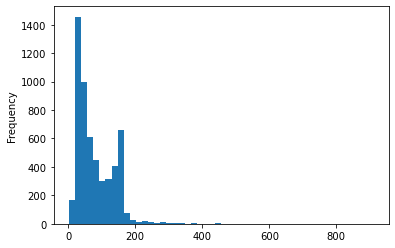

In [11]:
messages['length'].plot(bins=50, kind='hist')

In [13]:
messages.length.describe()

count    5572.000000
mean       80.489950
std        59.942907
min         2.000000
25%        36.000000
50%        62.000000
75%       122.000000
max       910.000000
Name: length, dtype: float64

In [ ]:
messages[messages['length']==910]['message'].iloc[0]

In [17]:
import string 
mess = 'Sample message! Notice: it is punctuation'
nopunc = [char for char in mess if char not in string.punctuation]
nopunc = ''.join(nopunc)

In [ ]:
from nltk.corpus import stopwords
stopwords.words('english')[0:10]

In [ ]:
nopunc.split()

In [ ]:
nopunc

In [21]:
def text_process(mess):
    nopunc = [char for char in mess if char not in string.punctuation]
    nopunc = ''.join(nopunc)
    return [word for word in nopunc.split() if word.lower() not in stopwords.words('english')]

In [ ]:
messages['message'].head(5).apply(text_process)

In [ ]:
messages.head()

In [24]:
from sklearn.feature_extraction.text import CountVectorizer

In [25]:
bow_transformer = CountVectorizer(analyzer=text_process).fit(messages['message'])
print(len(bow_transformer.vocabulary_))

11425


In [35]:
messages_bow = bow_transformer.transform(messages['message'])

In [36]:
print('shape of sparse matrix', messages_bow.shape)
print('amount of non zero occurance', messages_bow.nnz)

shape of sparse matrix (5572, 11425)
amount of non zero occurance 50548


In [37]:
sparsity = (100*messages_bow.nnz/(messages_bow.shape[0]*messages_bow.shape[1]))
print('sparsity:{}'.format(round(sparsity)))

sparsity:0


In [40]:
from sklearn.feature_extraction.text import TfidfTransformer

tfidf_transformer = TfidfTransformer().fit(messages_bow)

In [42]:
print(tfidf_transformer.idf_[bow_transformer.vocabulary_['u']])
print(tfidf_transformer.idf_[bow_transformer.vocabulary_['university']])

3.2800524267409408
8.527076498901426


In [43]:
messages_tfidf = tfidf_transformer.transform(messages_bow)
print(messages_tfidf.shape)

(5572, 11425)


In [44]:
# training of model 

In [47]:
from sklearn.naive_bayes import MultinomialNB
spam_detect_model = MultinomialNB().fit(messages_tfidf, messages['label'])

In [50]:
# model evaluation

In [52]:
all_predictions = spam_detect_model.predict(messages_tfidf)
print(all_predictions)

['ham' 'ham' 'spam' ... 'ham' 'ham' 'ham']


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(messages['label'], all_predictions))

In [59]:
from sklearn.model_selection import train_test_split

msg_train, msg_test, label_train, lable_test = \
train_test_split(messages['message'], messages['label'], test_size= 0.2)

In [60]:
# data pipeline

In [61]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('bow', CountVectorizer(analyzer=text_process)),
    ('tfidf', TfidfTransformer()),
    ('classifer', MultinomialNB()),
])

In [62]:
pipeline.fit(msg_train, label_train)

Pipeline(steps=[('bow',
                 CountVectorizer(analyzer=<function text_process at 0x000002BA928E45E0>)),
                ('tfidf', TfidfTransformer()), ('classifer', MultinomialNB())])

In [63]:
label_test_predictions = pipeline.predict(msg_test)

In [ ]:
print(classification_report(label_test_predictions, lable_test))